# Crime Incident Analysis
## Phase 4: Data Interpretation and Storytelling

**Final Google Colab notebook**

Upload through **File → Upload notebook**. Findings, tables and charts are saved inside. To recompute, choose **Runtime → Run all** and upload the original crime CSV when prompted. This notebook runs independently of the earlier phases.

Outputs were calculated in Python from the supplied dataset, outside a live Colab session.

**Purpose:** Turn the findings from Phases 1–3 into a coherent crime-domain story, explain plausible reasons without claiming unproven causes, and propose specific actions with evaluation measures.

**Story:** Understand which records dominate the observed reporting workload, assess timing and measurement limitations, then prioritize prevention questions and data-quality improvements.

**Important distinction:** These are recorded incidents. They are not a census of all crime, a prediction of individual behavior, or population-adjusted crime rates.

### 1. Load the data and prepare the evidence
Repeat essential preprocessing for reproducibility. Missing timestamps are not invented. Report dates use UTC. A recorded start–end window is not necessarily how long a crime lasted. All outliers remain in the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

filename = "Crime_Incidents_in_the_Last_30_Days (1).csv"
if not Path(filename).exists():
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))

df = pd.read_csv(filename).drop_duplicates().copy()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip().replace("", np.nan)
for col in ["OFFENSE", "METHOD", "SHIFT", "BLOCK"]:
    df[col] = df[col].fillna("Unknown")
for col in ["REPORT_DAT", "START_DATE", "END_DATE"]:
    df[col] = pd.to_datetime(df[col], format="%Y/%m/%d %H:%M:%S%z",
                             errors="coerce", utc=True)
df["Recorded_Interval_Hours"] = (df["END_DATE"] - df["START_DATE"]).dt.total_seconds()/3600
df.loc[df["Recorded_Interval_Hours"] < 0, "Recorded_Interval_Hours"] = np.nan
x = df["Recorded_Interval_Hours"].dropna()
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3-q1
flagged = (x < q1-1.5*iqr) | (x > q3+1.5*iqr)
n = len(df)
offense_counts = df["OFFENSE"].value_counts()
shift_counts = df["SHIFT"].value_counts()
theft_mask = df["OFFENSE"].str.contains("THEFT", case=False, na=False)
theft_n = int(theft_mask.sum())
missing_n = int(df["Recorded_Interval_Hours"].isna().sum())

report_day = df["REPORT_DAT"].dt.floor("D")
days = pd.date_range(report_day.min(), report_day.max(), freq="D")
daily = report_day.value_counts().reindex(days, fill_value=0).sort_index()
local_report = df["REPORT_DAT"].dt.tz_convert("America/New_York")

plt.style.use("dark_background")
plt.rcParams.update({"figure.figsize":(11,5), "font.size":10,
                     "axes.spines.top":False,"axes.spines.right":False})
print("Records:", n)
print("UTC reporting range:", df["REPORT_DAT"].min(), "to", df["REPORT_DAT"].max())
print("Washington, DC local reporting range:", local_report.min(), "to", local_report.max())
print("Observed UTC report dates:", len(daily))
print("Missing recorded intervals:", missing_n)

Records: 2073
UTC reporting range: 2026-09-23 07:09:57+00:00 to 2026-10-22 03:50:22+00:00
Washington, DC local reporting range: 2026-09-23 03:09:57-04:00 to 2026-10-21 23:50:22-04:00
Observed UTC report dates: 30
Missing recorded intervals: 178


### 2. Executive story: the evidence in five statements
Use these as the opening of the presentation. Counts refer to this file and reporting window. “Theft-related” includes every offense label containing THEFT, including motor vehicle theft.

In [2]:
summary = pd.DataFrame({
    "Finding": ["Recorded incident workload", "Theft-related records", "Most frequent recorded shift",
                "Typical recorded time window", "Interval data requiring careful interpretation"],
    "Evidence": [f"{n:,} records across {len(daily)} observed UTC report dates",
                 f"{theft_n:,} records ({theft_n/n*100:.1f}%)",
                 f"{shift_counts.index[0]}: {shift_counts.iloc[0]:,} records ({shift_counts.iloc[0]/n*100:.1f}%)",
                 f"Median {x.median():.2f} h; mean {x.mean():.2f} h; IQR {iqr:.2f} h",
                 f"{missing_n} missing intervals; {flagged.sum()} IQR flags among {len(x):,} available intervals"],
    "Domain meaning": ["Describes the recorded workload in this extract, not all crime",
                       "Supports prioritizing theft-prevention questions and victim information",
                       "Supports review of recorded workload timing; verify the shift definition",
                       "Median and IQR describe central windows more reliably than the mean alone",
                       "Data-quality review should precede precise occurrence-time conclusions"]
})
display(summary)

,Finding,Evidence,Domain meaning
0,Recorded incident workload,"2,073 records across 30 observed UTC report dates",Describes the recorded workload in this extrac...
1,Theft-related records,"1,718 records (82.9%)",Supports prioritizing theft-prevention questio...
2,Most frequent recorded shift,DAY: 906 records (43.7%),Supports review of recorded workload timing; v...
3,Typical recorded time window,Median 1.00 h; mean 17.84 h; IQR 2.74 h,Median and IQR describe central windows more r...
4,Interval data requiring careful interpretation,"178 missing intervals; 348 IQR flags among 1,8...",Data-quality review should precede precise occ...


### 3. Insight 1 — offense composition and prevention priorities
**Observation:** Compare the largest offense categories and theft-related share.

**Possible explanations to investigate:** Opportunities for theft, how quickly victims notice losses, and reporting/classification practices could influence the recorded mix. The dataset contains no exposure, victim survey or causal intervention data, so it cannot choose between these explanations.

**Domain value:** The composition identifies a useful prevention topic and the types of records needing attention. Frequency alone does not measure severity or justify reducing support for less frequent serious offenses.

Largest individual category: THEFT/OTHER — 1,005 records.
Next step: review theft subcategories separately before choosing prevention materials.


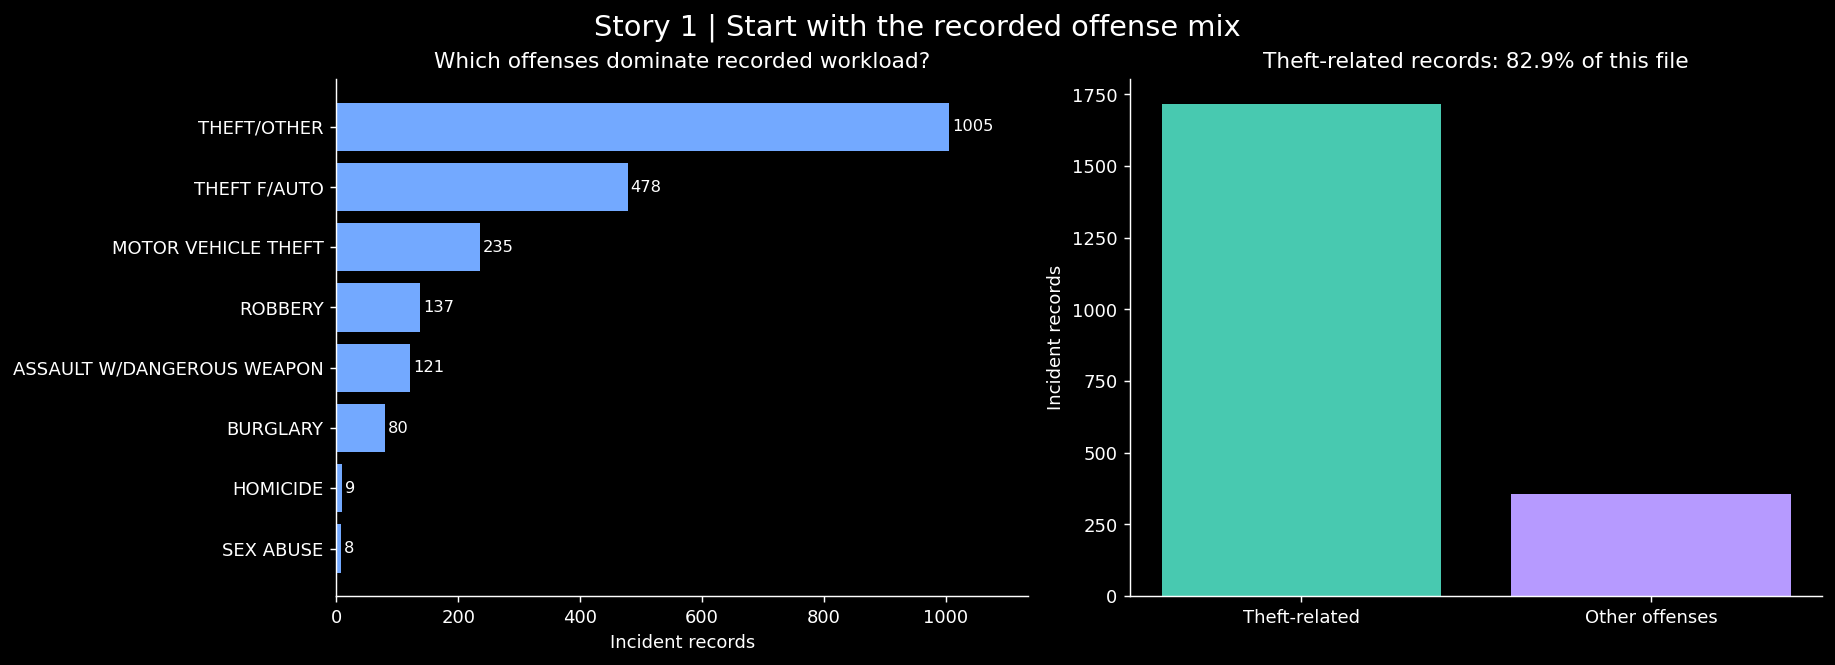

In [3]:
fig, axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
counts = offense_counts.sort_values()
axes[0].barh(counts.index, counts.values, color="#73a9ff")
axes[0].set(title="Which offenses dominate recorded workload?",xlabel="Incident records")
for i,value in enumerate(counts.values):
    axes[0].text(value+5,i,str(value),va="center",fontsize=9)
axes[0].set_xlim(0,counts.max()*1.13)
axes[1].bar(["Theft-related", "Other offenses"],[theft_n,n-theft_n],color=["#48c9b0","#b69aff"])
axes[1].set(title=f"Theft-related records: {theft_n/n*100:.1f}% of this file",ylabel="Incident records")
fig.suptitle("Story 1 | Start with the recorded offense mix",fontsize=16)
plt.show()
print(f"Largest individual category: {offense_counts.index[0]} — {offense_counts.iloc[0]:,} records.")
print("Next step: review theft subcategories separately before choosing prevention materials.")

### 4. Insight 2 — timing describes reporting workload, not a proven danger pattern
**Observation:** Compare recorded shifts and daily reports.

**Possible explanations to investigate:** Actual occurrence timing, delay before discovery/reporting, shift assignment rules and an incomplete final extraction day may affect the pattern. SHIFT must be checked against the source data dictionary before interpreting its meaning.

**Domain value:** Timing can guide a review of report-intake workload. It does not establish that a shift is intrinsically more dangerous or prove when extra operational staffing is needed.

**Boundary caution:** The first and last UTC dates can be partial. The graph marks both; a fall at the last date should not be presented as successful crime reduction.

Most frequent recorded shift: DAY (43.7%).
Verify shift definitions and comparable full extraction periods before staffing decisions.


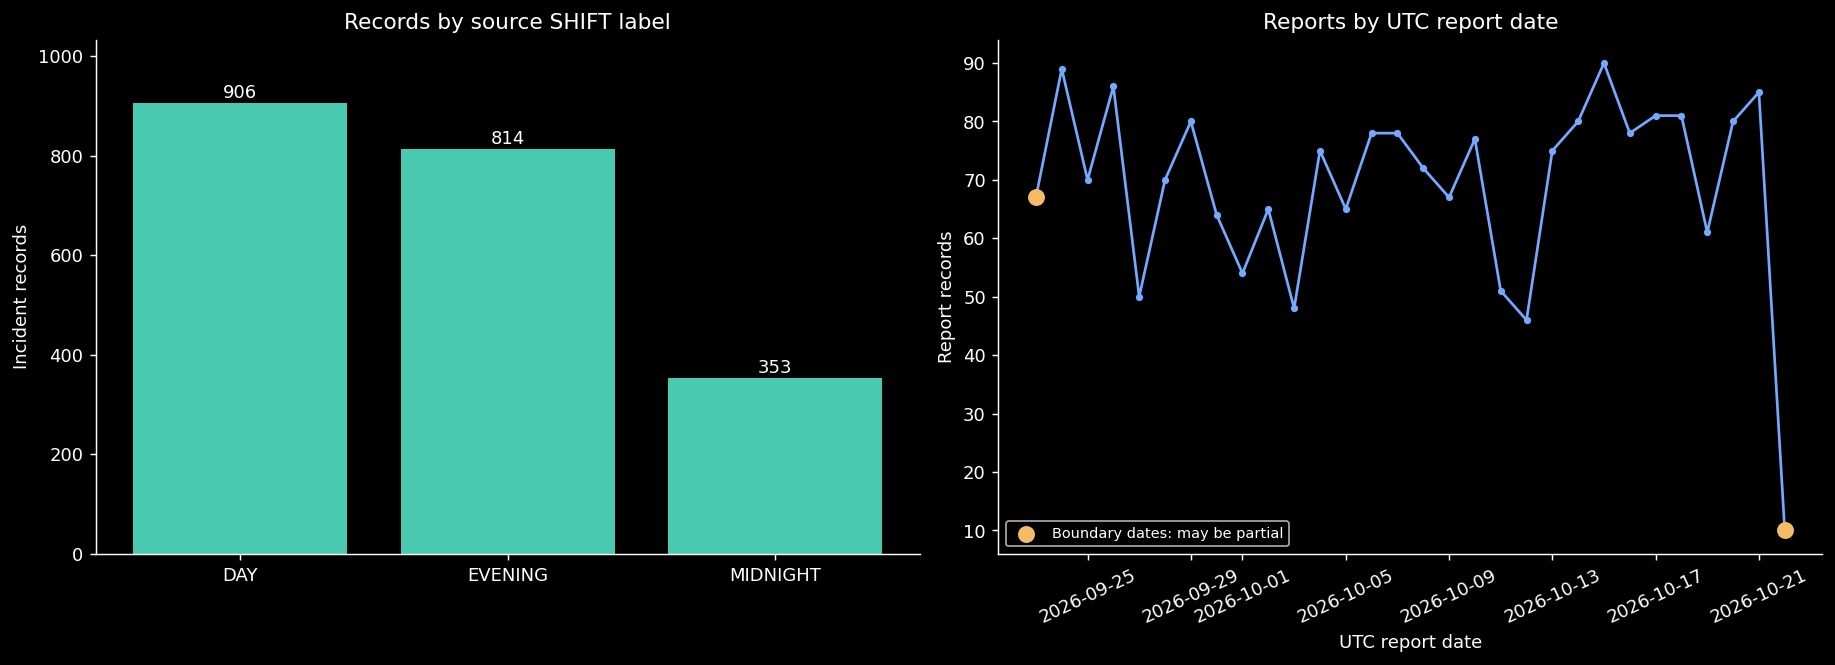

In [4]:
fig, axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
axes[0].bar(shift_counts.index,shift_counts.values,color="#48c9b0")
axes[0].set(title="Records by source SHIFT label",ylabel="Incident records")
for i,value in enumerate(shift_counts.values):
    axes[0].text(i,value+10,f"{value:,}",ha="center")
axes[0].set_ylim(0,shift_counts.max()*1.14)
axes[1].plot(daily.index,daily.values,marker="o",markersize=3,color="#73a9ff")
axes[1].scatter([daily.index[0],daily.index[-1]],[daily.iloc[0],daily.iloc[-1]],
                color="#f3bc65",s=70,label="Boundary dates: may be partial",zorder=3)
axes[1].set(title="Reports by UTC report date",ylabel="Report records",xlabel="UTC report date")
axes[1].tick_params(axis="x",rotation=25)
axes[1].legend(fontsize=8)
plt.show()
print(f"Most frequent recorded shift: {shift_counts.index[0]} ({shift_counts.iloc[0]/n*100:.1f}%).")
print("Verify shift definitions and comparable full extraction periods before staffing decisions.")

### 5. Insight 3 — long recorded windows change the average
**Observation:** Compare median, mean and IQR flags.

**Possible explanation to investigate:** An offense discovered later can have an uncertain start–end window. Long windows may be legitimate uncertainty, historical events reported recently, or data errors. Only source-record checks can distinguish them.

**Domain value:** Use median and IQR to communicate the typical recorded window. Audit long and missing windows before fine-grained occurrence-time analysis. Do not describe the average recorded window as average crime duration.

Maximum recorded window: 5,304.0 hours.
IQR-flagged: 18.4% of available intervals.
Missing intervals: 8.6% of all records.


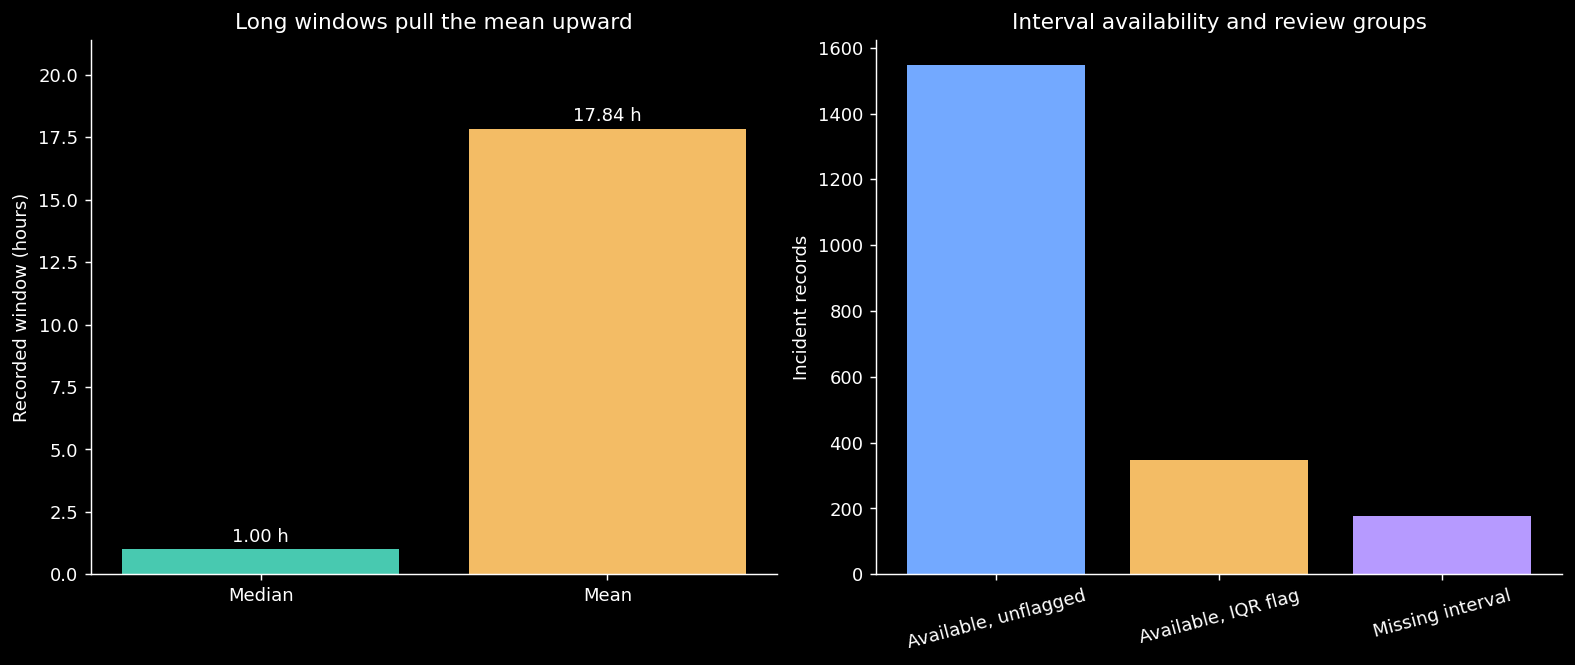

In [5]:
fig, axes = plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
axes[0].bar(["Median", "Mean"],[x.median(),x.mean()],color=["#48c9b0","#f3bc65"])
axes[0].set(title="Long windows pull the mean upward",ylabel="Recorded window (hours)")
for i,value in enumerate([x.median(),x.mean()]):
    axes[0].text(i,value+0.3,f"{value:.2f} h",ha="center")
axes[0].set_ylim(0,x.mean()*1.2)
review_counts = [int((~flagged).sum()),int(flagged.sum()),missing_n]
axes[1].bar(["Available, unflagged", "Available, IQR flag", "Missing interval"],review_counts,
             color=["#73a9ff","#f3bc65","#b69aff"])
axes[1].set(title="Interval availability and review groups",ylabel="Incident records")
axes[1].tick_params(axis="x",rotation=15)
plt.show()
print(f"Maximum recorded window: {x.max():,.1f} hours.")
print(f"IQR-flagged: {flagged.sum()/len(x)*100:.1f}% of available intervals.")
print(f"Missing intervals: {missing_n/n*100:.1f}% of all records.")
assert sum(review_counts) == n

### 6. Insight 4 — category-count correlations do not explain causes
**Observation:** Recompute daily category-count correlations from Phase 3.

**Possible explanations to investigate:** Shared reporting conditions, common day-level influences, chance and partial boundary dates could all affect associations. The short observation window does not identify a causal mechanism.

**Domain value:** Correlation helps frame questions for a longer analysis. It does not establish that one offense causes another or provide a reliable forecasting model.

In [6]:
daily_types = pd.DataFrame(index=days)
for label, pattern in [("Theft", "THEFT"),("Assault", "ASSAULT"),("Robbery", "ROBBERY")]:
    selected = df[df["OFFENSE"].str.contains(pattern,case=False,na=False)]
    daily_types[label] = selected.groupby(selected["REPORT_DAT"].dt.floor("D")).size().reindex(days,fill_value=0)
display(daily_types.corr().round(3))
print("Sensitivity check: exclude first and last UTC dates.")
display(daily_types.iloc[1:-1].corr().round(3))
print("Compare both tables before claiming that the association is stable.")

Sensitivity check: exclude first and last UTC dates.
Compare both tables before claiming that the association is stable.


,Theft,Assault,Robbery
Theft,1.000,0.224,0.110
Assault,0.224,1.000,-0.172
Robbery,0.110,-0.172,1.000


,Theft,Assault,Robbery
Theft,1.000,0.062,-0.064
Assault,0.062,1.000,-0.317
Robbery,-0.064,-0.317,1.000


### 7. Contextualization: connect the findings to crime-domain decisions
| Finding | Relevant users | Practical domain value | Additional evidence needed |
|---|---|---|---|
| Large theft-related share | Community prevention teams, victim-information services | Decide which prevention questions and information materials to review first | Theft subtypes, community feedback, exposure and reporting patterns |
| Unequal counts across recorded shifts | Report-intake supervisors | Review workload distribution and service demand | Official shift definition, full periods, staffing and response/service data |
| Long or missing time windows | Records and data-quality teams | Improve timestamp completeness and avoid misleading occurrence-time summaries | Source incident files and timestamp entry rules |
| Geographic concentrations in Phase 3 | Public-service analysts and community planners | Generate questions about places and environmental conditions | Population, footfall, land use, reporting coverage and community context |
| Short-window correlations | Analysts | Design a longer validation study | Multiple months and comparable extraction windows |

The application here is **crime reporting and community safety**. Healthcare or agriculture examples are not needed because the guidelines offer those as examples, not required domains. A location with more records must not be labelled more dangerous without population/exposure and reporting context.

### 8. Actionable recommendations with owners and evaluation measures
These are proposed next steps, not interventions proven effective by this dataset. Validate feasibility with the relevant team. Review priorities below reflect evidence and dependencies, not a ranking of offense severity.

In [7]:
recommendations = pd.DataFrame([
    ["1. Validate the reporting window", "Data analyst",
     "Check extraction timestamp and source shift/time definitions; label partial dates; use comparable complete periods for future comparisons.",
     "Before publishing trend or shift conclusions",
     "Documented extraction coverage and time definitions; complete-period count reconciliation"],
    ["2. Review timestamp quality", "Records/data-quality team",
     f"Review {missing_n} missing interval records and {int(flagged.sum())} flagged windows; retain legitimate long windows and correct only confirmed errors.",
     "Before precise occurrence-time analysis",
     "Number reviewed; confirmed errors corrected; remaining missingness; documented reason codes"],
    ["3. Scope a theft-prevention pilot", "Community prevention team",
     f"Use the {theft_n:,} theft-related records to review subtypes and consult community needs before selecting targeted information or prevention measures.",
     "After subtype and context review",
     "Pilot reach and participation; subtype reports over comparable periods; use a suitable comparison group where feasible"],
    ["4. Validate workload timing", "Report-intake supervisor",
     "Compare verified shift-level intake counts across multiple complete periods with service and staffing data before changing schedules.",
     "After shift-definition validation",
     "Records per staffed hour; intake/service delay; coverage by verified shift"],
    ["5. Expand and contextualize the dataset", "Project/data team",
     "Add comparable historical periods and relevant population or exposure data before location risk comparisons or predictive claims.",
     "Before risk mapping or forecasting",
     "Months covered; definition consistency; missingness; availability and suitability of exposure denominators"]
], columns=["Action", "Suggested owner", "Concrete next step", "When", "How to evaluate"])
display(recommendations)

,Action,Suggested owner,Concrete next step,When,How to evaluate
0,1. Validate the reporting window,Data analyst,Check extraction timestamp and source shift/ti...,Before publishing trend or shift conclusions,Documented extraction coverage and time defini...
1,2. Review timestamp quality,Records/data-quality team,Review 178 missing interval records and 348 fl...,Before precise occurrence-time analysis,Number reviewed; confirmed errors corrected; r...
2,3. Scope a theft-prevention pilot,Community prevention team,"Use the 1,718 theft-related records to review ...",After subtype and context review,Pilot reach and participation; subtype reports...
3,4. Validate workload timing,Report-intake supervisor,Compare verified shift-level intake counts acr...,After shift-definition validation,Records per staffed hour; intake/service delay...
4,5. Expand and contextualize the dataset,Project/data team,Add comparable historical periods and relevant...,Before risk mapping or forecasting,Months covered; definition consistency; missin...


### 9. Presentation storyline
A clear sequence for the group presentation is **question → evidence → explanation to investigate → domain value → action**. Use the computed figures below; do not claim the hypotheses have been verified.

In [8]:
story = [
    f"We analyzed {n:,} recorded incidents across {len(daily)} UTC report dates to understand the offense mix and the quality of time information.",
    f"Theft-related offenses account for {theft_n/n*100:.1f}% of records. This makes theft prevention a useful topic to investigate, while maintaining attention to less frequent serious offenses.",
    f"The {shift_counts.index[0]} label contains the most records. Reporting delay and shift assignment rules may affect this pattern, so we would verify definitions before proposing staffing changes.",
    f"The mean recorded window is {x.mean():.2f} hours, but the median is {x.median():.2f} hour. This difference reflects the influence of long windows; it does not mean a typical crime lasted that long.",
    f"There are {missing_n} missing windows and {int(flagged.sum())} IQR flags among available windows. We recommend source-record review, preserving valid uncertainty rather than deleting it.",
    "Our next steps are to validate coverage and timestamps, review theft subtypes with community context, and evaluate any pilot using comparable periods and appropriate measures."
]
for i, paragraph in enumerate(story,1):
    print(f"{i}. {paragraph}")
    print()

1. We analyzed 2,073 recorded incidents across 30 UTC report dates to understand the offense mix and the quality of time information.

2. Theft-related offenses account for 82.9% of records. This makes theft prevention a useful topic to investigate, while maintaining attention to less frequent serious offenses.

3. The DAY label contains the most records. Reporting delay and shift assignment rules may affect this pattern, so we would verify definitions before proposing staffing changes.

4. The mean recorded window is 17.84 hours, but the median is 1.00 hour. This difference reflects the influence of long windows; it does not mean a typical crime lasted that long.

5. There are 178 missing windows and 348 IQR flags among available windows. We recommend source-record review, preserving valid uncertainty rather than deleting it.

6. Our next steps are to validate coverage and timestamps, review theft subtypes with community context, and evaluate any pilot using comparable periods and app

### 10. Limitations and likely faculty questions
| Question | Defensible answer |
|---|---|
| Why is theft prominent? | It is prominent in the recorded mix. Opportunity, reporting and discovery patterns are hypotheses; the file cannot establish which caused it. |
| Does the busiest shift mean the most dangerous time? | No. First verify the source shift definition and reporting process. Counts are not exposure-adjusted risk. |
| Why retain outliers? | Long windows can be legitimate uncertainty. IQR flags identify records to review; they do not prove errors. |
| Why use the median? | Long windows pull the mean upward. Median and IQR better communicate the center and spread without deleting those windows. |
| Did crime fall at the end? | The final extraction date may be incomplete. Comparable complete periods are required. |
| Can correlation explain why crime happens? | No. It measures association among daily recorded counts and is sensitive to the observation window. |
| Have the recommended actions been proven to reduce crime? | No. They are evidence-informed proposals; implementation and outcome evaluation require additional data. |

Other limits: this is a short reporting extract, occurrence dates can predate report dates, missingness may be nonrandom, block positions are not exact event locations, and the data do not include unreported crime or exposure denominators.

### Phase 4 completion checklist
| Requirement | Where it is addressed |
|---|---|
| Insight extraction beyond graph descriptions | Sections 3–6: observation, plausible explanations, verification needs and domain value |
| Contextualization | Section 7: crime-reporting and community-safety applications |
| Actionable recommendations | Section 8: specific steps, suggested owners, timing and evaluation measures |
| Coherent storytelling | Sections 2 and 9: executive findings and presentation sequence |
| Interpretation limits | Section 10: uncertainty and faculty Q&A |

### Conclusion
The dataset supports a description of recorded workload and identifies practical questions for prevention and data-quality review. The most defensible immediate actions are to validate extraction coverage, review uncertain timestamps, and investigate the dominant theft subtypes with context. Stronger claims about causes, location risk or intervention success require further evidence.

**Sources:** Supplied Crime_Incidents_in_the_Last_30_Days (1).csv; supplied FDS Mini Competition Guidelines and evaluation rubric. All numerical claims above are computed from the supplied file. Explanations and proposed actions are explicitly labelled; no external causal findings are asserted.